# Problema 6 — Regresión reproducible sobre Airfoil Self-Noise

- **6a:** datos crudos, auditoría, partición y EDA en desarrollo.
- **6b:** validación cruzada de la referencia, OLS, Ridge y Lasso en dos representaciones.
- **6c:** evaluación única en prueba de los finalistas.
- **6d:** alcance de la evaluación y elección del modelo.

Objetivo: predecir `sonido` (dB) a partir de `frecuencia`, `angulo`, `cuerda`, `velocidad` y `espesor`.

## 0. Pregunta e hipótesis

Queremos saber qué condiciones del ensayo influyen en el ruido que produce un perfil aerodinámico.
Cada fila es una medición en el túnel de viento: un perfil de cierta cuerda, con un ángulo de ataque
y una velocidad del flujo, medido a una frecuencia. La variable a predecir es `sonido`, el nivel de
presión sonora en dB, y la dejamos en esa unidad.

Antes de explorar los datos esperábamos lo siguiente:

1. El ruido no sube ni baja de forma continua con la frecuencia, sino que tiene un máximo en algún punto.
2. A mayor velocidad del flujo, mayor nivel de ruido.
3. `espesor` y `angulo` dan información parecida, porque el espesor de la capa límite depende del ángulo.

Estas hipótesis solo se revisan con el EDA; para darlas por buenas hay que comprobarlas después con
validación cruzada y con el conjunto de prueba.

### Diccionario de variables

| Variable | Nombre UCI | Rol | Unidad | Significado | Dominio conocido |
|---|---|---|---|---|---|
| `frecuencia` | frequency | entrada | Hz | Frecuencia a la que se mide el ruido | > 0 |
| `angulo` | attack-angle | entrada | grados | Ángulo de ataque del perfil | ≥ 0 |
| `cuerda` | chord-length | entrada | m | Longitud de cuerda del perfil | > 0 |
| `velocidad` | free-stream-velocity | entrada | m/s | Velocidad del flujo libre | > 0 |
| `espesor` | suction-side-displacement-thickness | entrada | m | Espesor de desplazamiento en el lado de succión | > 0 |
| `sonido` | scaled-sound-pressure | objetivo | dB | Nivel de presión sonora escalado | > 0 |

Fuente: UCI Machine Learning Repository, *Airfoil Self-Noise*, id 291 (ensayos de la NASA).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import sklearn
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit

print(f"NumPy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | scikit-learn {sklearn.__version__}")

SEMILLA = 2026
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATOS = RAIZ / "data" / "airfoil_self_noise.dat"
RUTA_RES = RAIZ / "resultados"
RUTA_RES.mkdir(exist_ok=True)

ENTRADAS = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor"]
OBJETIVO = "sonido"
COLS = ENTRADAS + [OBJETIVO]
UNIDADES = {"frecuencia": "Hz", "angulo": "grados", "cuerda": "m",
            "velocidad": "m/s", "espesor": "m", "sonido": "dB"}

NumPy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2 | scikit-learn 1.9.1


## 1. Datos crudos e identificador estable

El archivo no se modifica. Cada fila recibe un `id` igual a su posición en el archivo original:
no depende de ningún orden posterior ni de la partición.

In [2]:
crudo = pd.read_csv(RUTA_DATOS, sep="\t", header=None, names=COLS)
crudo.insert(0, "id", np.arange(len(crudo)))
print(crudo.shape)
crudo.head()

(1503, 7)


,id,frecuencia,angulo,cuerda,velocidad,espesor,sonido
0,0,800,0.0,0.3048,71.3,0.002663,126.201
1,1,1000,0.0,0.3048,71.3,0.002663,125.201
2,2,1250,0.0,0.3048,71.3,0.002663,125.951
3,3,1600,0.0,0.3048,71.3,0.002663,127.591
4,4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Chequeos previos a la partición

Solo formato, identidad y dominios conocidos. **No** se calculan imputaciones, cuantiles ni
transformaciones sobre la base completa.

In [3]:
print("Tipos:\n", crudo.dtypes, sep="")
print("\nFaltantes:\n", crudo.isna().sum(), sep="")
print("\nValores distintos:\n", crudo[COLS].nunique(), sep="")

Tipos:
id              int64
frecuencia      int64
angulo        float64
cuerda        float64
velocidad     float64
espesor       float64
sonido        float64
dtype: object

Faltantes:
id            0
frecuencia    0
angulo        0
cuerda        0
velocidad     0
espesor       0
sonido        0
dtype: int64

Valores distintos:
frecuencia      21
angulo          27
cuerda           6
velocidad        4
espesor        105
sonido        1456
dtype: int64


In [4]:
dup_exactos = crudo[COLS].duplicated(keep=False)
dup_entradas = crudo[ENTRADAS].duplicated(keep=False)
print("Filas en duplicados exactos:", dup_exactos.sum())
print("Filas con entradas repetidas y sonido distinto:", (dup_entradas & ~dup_exactos).sum())

Filas en duplicados exactos: 0
Filas con entradas repetidas y sonido distinto: 0


In [5]:
# Dominios conocidos por la física del experimento (no estimados con los datos).
dominios = {
    "frecuencia": lambda s: s > 0,      # Hz
    "angulo":     lambda s: s >= 0,     # grados; ángulo de ataque no negativo en el ensayo
    "cuerda":     lambda s: s > 0,      # m
    "velocidad":  lambda s: s > 0,      # m/s
    "espesor":    lambda s: s > 0,      # m
    "sonido":     lambda s: s > 0,      # dB
}
auditoria = pd.DataFrame({
    "unidad": ["Hz", "grados", "m", "m/s", "m", "dB"],
    "min": crudo[COLS].min(),
    "max": crudo[COLS].max(),
    "fuera_de_dominio": [int((~dominios[c](crudo[c])).sum()) for c in COLS],
})
auditoria

,unidad,min,max,fuera_de_dominio
frecuencia,Hz,200.000000,20000.000000,0
angulo,grados,0.000000,22.200000,0
cuerda,m,0.025400,0.304800,0
velocidad,m/s,31.700000,71.300000,0
espesor,m,0.000401,0.058411,0
sonido,dB,103.380000,140.987000,0


**Auditoría y limpieza.** No se encontraron faltantes, duplicados exactos ni valores fuera de los
dominios físicos. Por tanto, **no se aplica ninguna regla de limpieza**: se trabaja con las 1503 filas
originales. El metadato de UCI que clasifica `attack-angle` como *Binary* es incorrecto: el ángulo
toma 27 valores entre 0° y 22,2°, por lo que se trata como variable continua.

## 3. Partición desarrollo (80 %) / prueba (20 %)

Los duplicados exactos deben quedar del mismo lado. Se agrupan las filas por su contenido
y se parte por grupos.

In [6]:
grupos = pd.util.hash_pandas_object(crudo[COLS], index=False).to_numpy()
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_dev, idx_test = next(gss.split(crudo, groups=grupos))

dev = crudo.iloc[idx_dev].reset_index(drop=True)
test = crudo.iloc[idx_test].reset_index(drop=True)
print(f"Desarrollo: {len(dev)} filas ({len(dev)/len(crudo):.1%}) | Prueba: {len(test)} filas")

Desarrollo: 1202 filas (80.0%) | Prueba: 301 filas


In [7]:
# Verificaciones de la partición
assert len(set(dev["id"]) & set(test["id"])) == 0, "Hay ids en ambos conjuntos"
assert len(dev) + len(test) == len(crudo), "Se perdieron o duplicaron filas"
assert len(set(grupos[idx_dev]) & set(grupos[idx_test])) == 0, "Duplicados repartidos"

manifiesto = pd.DataFrame({"id": crudo["id"], "conjunto": "desarrollo"})
manifiesto.loc[manifiesto["id"].isin(test["id"]), "conjunto"] = "prueba"
manifiesto.to_csv(RUTA_RES / "airfoil_particion.csv", index=False)
manifiesto["conjunto"].value_counts()

conjunto
desarrollo    1202
prueba         301
Name: count, dtype: int64

## 4. EDA — solo en desarrollo

A partir de aquí **no se mira `test`**.

### 4.1 Univariado

In [8]:
resumen = dev[COLS].describe().T
resumen["mediana"] = dev[COLS].median()
resumen["iqr"] = resumen["75%"] - resumen["25%"]
resumen["asimetria"] = dev[COLS].skew()
resumen["curtosis_exceso"] = dev[COLS].kurt()
resumen.round(4)

,count,mean,std,min,25%,50%,75%,max,mediana,iqr,asimetria,curtosis_exceso
frecuencia,1202.0,2847.7496,3062.6622,200.0000,800.0000,1600.0000,4000.0000,20000.0000,1600.0000,3200.0000,2.0722,5.3246
angulo,1202.0,6.8050,5.9215,0.0000,2.0000,5.4000,11.2000,22.2000,5.4000,9.2000,0.6906,-0.4036
cuerda,1202.0,0.1372,0.0937,0.0254,0.0508,0.1016,0.2286,0.3048,0.1016,0.1778,0.4477,-1.0482
velocidad,1202.0,51.3040,15.5199,31.7000,39.6000,55.5000,71.3000,71.3000,55.5000,31.7000,0.1855,-1.5738
espesor,1202.0,0.0112,0.0133,0.0004,0.0025,0.0049,0.0161,0.0584,0.0049,0.0136,1.7133,2.2590
sonido,1202.0,124.8275,6.9722,103.3800,120.1362,125.7225,130.0498,140.9870,125.7225,9.9135,-0.4126,-0.3346


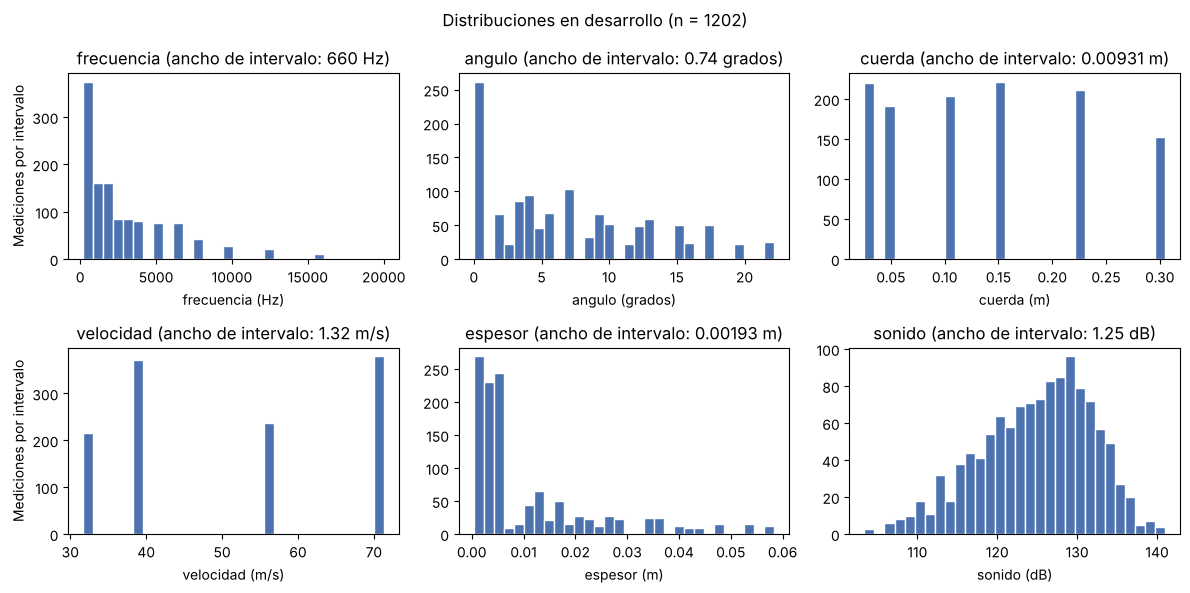

In [9]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 6))
for eje, c in zip(ejes.ravel(), COLS):
    _, bordes, _ = eje.hist(dev[c], bins=30, color="#4C72B0", edgecolor="white")
    ancho = bordes[1] - bordes[0]
    eje.set(title=f"{c} (ancho de intervalo: {ancho:.3g} {UNIDADES[c]})",
            xlabel=f"{c} ({UNIDADES[c]})")
for eje in ejes[:, 0]:
    eje.set_ylabel("Mediciones por intervalo")
fig.suptitle(f"Distribuciones en desarrollo (n = {len(dev)})")
fig.tight_layout()

In [10]:
# Valores fuera de los bigotes (1.5 IQR): se cuentan, NO se eliminan.
def fuera_de_bigotes(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: fuera_de_bigotes(dev[c]) for c in COLS}, name="n_fuera_bigotes")

frecuencia     62
angulo          0
cuerda          0
velocidad       0
espesor       100
sonido          3
Name: n_fuera_bigotes, dtype: int64

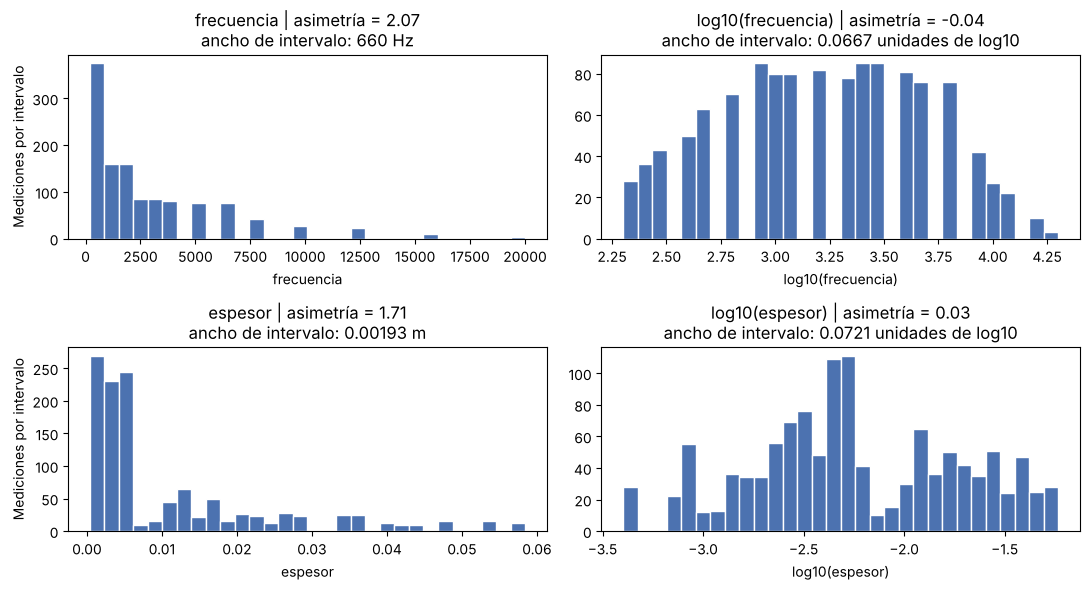

In [11]:
# ¿La escala logarítmica reduce la asimetría de las entradas con cola derecha?
fig, ejes = plt.subplots(2, 2, figsize=(11, 6))
for fila, c in enumerate(["frecuencia", "espesor"]):
    versiones = [(dev[c], c, UNIDADES[c]),
                 (np.log10(dev[c]), f"log10({c})", "unidades de log10")]
    for col, (datos, etiqueta, unidad) in enumerate(versiones):
        _, bordes, _ = ejes[fila, col].hist(datos, bins=30, color="#4C72B0", edgecolor="white")
        ancho = bordes[1] - bordes[0]
        ejes[fila, col].set(
            title=f"{etiqueta} | asimetría = {datos.skew():.2f}\nancho de intervalo: {ancho:.3g} {unidad}",
            xlabel=etiqueta)
    ejes[fila, 0].set_ylabel("Mediciones por intervalo")
fig.tight_layout()

### 4.2 Asociación

In [12]:
spearman = dev[COLS].corr(method="spearman")[OBJETIVO]
pearson = dev[COLS].corr(method="pearson")[OBJETIVO]
pd.DataFrame({"pearson": pearson, "spearman": spearman}).drop(OBJETIVO)

,pearson,spearman
frecuencia,-0.395222,-0.332750
angulo,-0.167442,-0.142392
cuerda,-0.221297,-0.237314
velocidad,0.130471,0.121586
espesor,-0.334221,-0.292229


In [13]:
corr_entradas = dev[ENTRADAS].corr(method="spearman")
display(corr_entradas.round(2))

# Pares de entradas con asociación fuerte (|rho| >= 0.8): posible redundancia.
triangulo = corr_entradas.where(np.triu(np.ones(corr_entradas.shape), k=1).astype(bool))
pares = triangulo.stack().rename("spearman").reset_index()
pares.columns = ["variable_1", "variable_2", "spearman"]
pares.loc[pares["spearman"].abs() >= 0.8]

,frecuencia,angulo,cuerda,velocidad,espesor
frecuencia,1.00,-0.29,-0.01,0.10,-0.34
angulo,-0.29,1.00,-0.49,0.06,0.87
cuerda,-0.01,-0.49,1.00,0.01,-0.08
velocidad,0.10,0.06,0.01,1.00,-0.00
espesor,-0.34,0.87,-0.08,-0.00,1.00


,variable_1,variable_2,spearman
9,angulo,espesor,0.874015


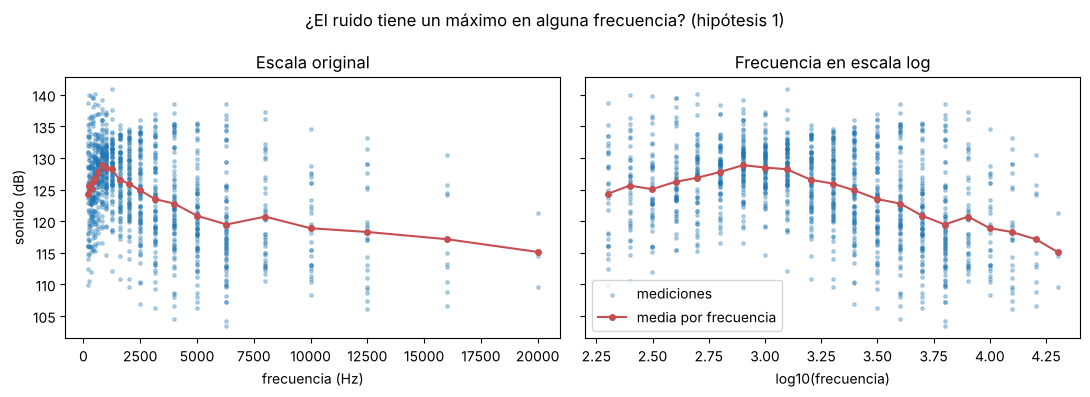

In [14]:
medias = dev.groupby("frecuencia")[OBJETIVO].mean()

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, transformar, etiqueta, titulo in [
        (ejes[0], lambda f: f, "frecuencia (Hz)", "Escala original"),
        (ejes[1], np.log10, "log10(frecuencia)", "Frecuencia en escala log")]:
    eje.scatter(transformar(dev["frecuencia"]), dev[OBJETIVO], s=6, alpha=0.3, label="mediciones")
    eje.plot(transformar(medias.index), medias.values, color="#C44E52", marker="o", ms=4,
             label="media por frecuencia")
    eje.set(xlabel=etiqueta, title=titulo)
ejes[0].set_ylabel("sonido (dB)")
ejes[1].legend()
fig.suptitle("¿El ruido tiene un máximo en alguna frecuencia? (hipótesis 1)")
fig.tight_layout()

**Lectura.** En escala log, la media del ruido sube hasta cerca de 1000 Hz y después baja. La relación
no es monótona, así que un término lineal en la frecuencia no basta.

### 4.3 Por grupos (con tamaños de grupo)

In [15]:
por_velocidad = dev.groupby("velocidad")[OBJETIVO].agg(["count", "mean", "median", "std"])
por_cuerda = dev.groupby("cuerda")[OBJETIVO].agg(["count", "mean", "median", "std"])
display(por_velocidad.round(2), por_cuerda.round(2))

# Mediana del sonido y tamaño de cada celda cuerda x velocidad
display(dev.pivot_table(values=OBJETIVO, index="cuerda", columns="velocidad", aggfunc="median").round(1))
display(pd.crosstab(dev["cuerda"], dev["velocidad"]))

,count,mean,median,std
velocidad,,,,
31.7,215,124.20,124.52,6.71
39.6,372,123.59,124.28,7.11
55.5,236,125.62,126.16,6.37
71.3,379,125.90,126.90,7.13


,count,mean,median,std
cuerda,,,,
0.0254,220,126.91,127.30,6.49
0.0508,191,126.55,127.22,6.14
0.1016,204,125.99,127.83,7.82
0.1524,222,122.55,123.52,7.37
0.2286,212,124.26,124.32,6.18
0.3048,153,122.22,123.07,6.01


velocidad,31.7,39.6,55.5,71.3
cuerda,,,,
0.0254,128.6,126.0,126.9,128.6
0.0508,124.5,126.6,127.9,129.3
0.1016,125.9,124.6,128.7,129.9
0.1524,123.8,120.5,125.2,124.9
0.2286,123.4,123.7,124.9,125.4
0.3048,122.1,122.8,123.2,125.2


velocidad,31.7,39.6,55.5,71.3
cuerda,,,,
0.0254,46,69,43,62
0.0508,31,60,36,64
0.1016,31,65,42,66
0.1524,34,73,41,74
0.2286,44,54,48,66
0.3048,29,51,26,47


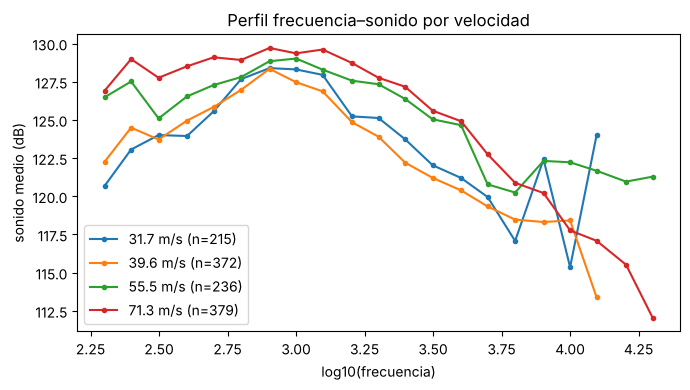

In [16]:
fig, eje = plt.subplots(figsize=(7, 4))
for v, g in dev.groupby("velocidad"):
    m = g.groupby("frecuencia")[OBJETIVO].mean()
    eje.plot(np.log10(m.index), m.values, marker="o", ms=3, label=f"{v} m/s (n={len(g)})")
eje.set(xlabel="log10(frecuencia)", ylabel="sonido medio (dB)",
        title="Perfil frecuencia–sonido por velocidad")
eje.legend()
fig.tight_layout()

**Lectura.** Cada línea compara las velocidades a la misma frecuencia. Las curvas de mayor
velocidad tienden a ir por encima (apoya H2) y todas tienen su máximo cerca de 1000 Hz.
Como son casi paralelas, la velocidad sube el nivel de ruido sin cambiar la forma del espectro:
basta incluirla como término lineal, sin interacción con la frecuencia. Por encima de
~6300 Hz (log10 f ≈ 3,8) las curvas se vuelven irregulares porque hay pocas mediciones.

## 5. Síntesis: de hallazgos a decisiones

Todas las decisiones de esta tabla se toman solo con desarrollo.

| # | Hipótesis | Hallazgo y evidencia | Decisión | Riesgo de fuga |
|---|---|---|---|---|
| H1 | El sonido no es monótono en la frecuencia | Perfil en U invertida en log10(frecuencia), máximo cerca de 1000 Hz, en las cuatro velocidades; Pearson −0,40 | Representación alternativa con `log10(frecuencia)` y su cuadrado | Nulo: transformación fija, sin parámetros estimados |
| H2 | Mayor velocidad, más ruido | Medias de 124,2 a 125,9 dB entre 31,7 y 71,3 m/s (n ≥ 215 por grupo); efecto pequeño frente a la dispersión (≈ 7 dB) | Conservar `velocidad` sin transformar | Nulo |
| H3 | `espesor` y `angulo` son redundantes | Spearman 0,87 entre ambas; `espesor` muy asimétrico (100 valores fuera de bigotes) | Conservar ambas y comparar con Ridge y Lasso, que tratan la redundancia | La estandarización se ajusta dentro de cada pliegue |

**Otros hallazgos.** Sin faltantes ni duplicados: no hay limpieza. Los valores fuera de bigotes son
mediciones válidas del diseño experimental y se conservan. Las frecuencias extremas tienen pocas
observaciones por velocidad, por lo que sus medias son inestables.

**Segmentos para el 6c).** Frecuencia baja y alta, con el umbral en la mediana de `frecuencia` en desarrollo.

In [17]:
UMBRAL_FRECUENCIA = float(dev["frecuencia"].median())   # estimado solo con desarrollo
def segmento(df):
    return np.where(df["frecuencia"] <= UMBRAL_FRECUENCIA, "frecuencia_baja", "frecuencia_alta")

print(f"Umbral: {UMBRAL_FRECUENCIA:.0f} Hz")
pd.Series(segmento(dev)).value_counts()

Umbral: 1600 Hz


frecuencia_baja    617
frecuencia_alta    585
Name: count, dtype: int64

## 6b. Comparación por validación cruzada

### Representaciones

Las dos son lineales en los parámetros y no estiman nada con los datos, así que se pueden calcular
antes de partir sin riesgo de fuga. Lo que sí se estima, la estandarización, se ajusta dentro de
cada pliegue.

| Representación | Variables | Transformaciones |
|---|---|---|
| Original | `frecuencia`, `angulo`, `cuerda`, `velocidad`, `espesor` | ninguna |
| Alternativa | `log_f`, `log_f2`, `angulo`, `cuerda`, `velocidad`, `espesor` | 2, motivadas por H1 |

- `log_f = log10(frecuencia)`. Dominio: frecuencia > 0 Hz, aquí entre 2,30 y 4,30. Unidad: log10(Hz).
- `log_f2 = log_f²`. Unidad: log10(Hz)². Junto con `log_f` permite una parábola en log-frecuencia,
  que es la forma de U invertida que mostró el EDA.

In [18]:
import sys
import json
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

sys.path.append(str(RAIZ))
from src.modelos import OLS, Ridge, LassoProximal


def rep_original(df):
    return df[ENTRADAS].to_numpy(dtype=float)


def rep_alternativa(df):
    log_f = np.log10(df["frecuencia"].to_numpy(dtype=float))
    resto = df[["angulo", "cuerda", "velocidad", "espesor"]].to_numpy(dtype=float)
    return np.column_stack([log_f, log_f ** 2, resto])


REPRESENTACIONES = {"original": rep_original, "alternativa": rep_alternativa}
NOMBRES_X = {"original": ENTRADAS,
             "alternativa": ["log_f", "log_f2", "angulo", "cuerda", "velocidad", "espesor"]}

### Reglas fijadas antes de ver resultados

- Cinco pliegues sobre desarrollo, con mezcla y semilla 2026. Todos los candidatos usan los mismos.
- Grilla de regularización: λ ∈ {0,001; 0,01; 0,1; 1; 10}, la misma del problema 5. En Ridge es λ₂ y
  en Lasso es λ₁, con la convención (4) del taller.
- Criterio principal: RMSE medio entre pliegues. También se reporta el MAE.
- Referencias: la media del entrenamiento del pliegue (para MSE/RMSE) y la mediana (para MAE).
- **Candidato regularizado:** el Ridge o Lasso, en cualquiera de las dos representaciones, con menor
  RMSE medio. La representación de los finalistas es la de ese candidato.
- **Desempate:** dos candidatos empatan si su RMSE medio difiere en menos de 0,01 dB. En empate se
  prefiere el de mayor λ (más regularizado) y, si persiste, Ridge, cuya solución es única.
- Lasso se ajusta con `tol = 1e-6` y `max_iter = 50 000`; se registra si convergió en cada ajuste.

In [19]:
GRILLA = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
TOL_EMPATE = 0.01
y_dev = dev[OBJETIVO].to_numpy(dtype=float)

kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
pliegues = list(kf.split(dev))

# Manifiesto de pliegues: en qué pliegue de validación cae cada id
asignacion = np.empty(len(dev), dtype=int)
for k, (_, idx_val) in enumerate(pliegues):
    asignacion[idx_val] = k
pd.DataFrame({"id": dev["id"], "pliegue_validacion": asignacion}).to_csv(
    RUTA_RES / "airfoil_pliegues.csv", index=False)
pd.Series(asignacion).value_counts().sort_index().rename("filas_en_validacion")

0    241
1    241
2    240
3    240
4    240
Name: filas_en_validacion, dtype: int64

In [20]:
def candidatos():
    yield "OLS", np.nan, lambda: OLS()
    for lam in GRILLA:
        yield "Ridge", lam, lambda lam=lam: Ridge(lambda2=lam)
    for lam in GRILLA:
        yield "Lasso", lam, lambda lam=lam: LassoProximal(lambda1=lam, tol=1e-6, max_iter=50_000)


def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))


def mae(y, p):
    return float(np.mean(np.abs(y - p)))


filas = []
for k, (idx_ent, idx_val) in enumerate(pliegues):
    y_ent, y_val = y_dev[idx_ent], y_dev[idx_val]

    # Referencias constantes, estimadas con el entrenamiento del pliegue
    for nombre, valor in [("Referencia media", y_ent.mean()), ("Referencia mediana", np.median(y_ent))]:
        p = np.full(len(y_val), valor)
        filas.append(dict(pliegue=k, representacion="-", modelo=nombre, lam=np.nan,
                          rmse=rmse(y_val, p), mae=mae(y_val, p), convergio=True))

    for rep, f_rep in REPRESENTACIONES.items():
        escalador = StandardScaler().fit(f_rep(dev.iloc[idx_ent]))   # solo entrenamiento del pliegue
        X_ent = escalador.transform(f_rep(dev.iloc[idx_ent]))
        X_val = escalador.transform(f_rep(dev.iloc[idx_val]))
        for nombre, lam, crear in candidatos():
            m = crear().fit(X_ent, y_ent)
            p = m.predict(X_val)
            filas.append(dict(pliegue=k, representacion=rep, modelo=nombre, lam=lam,
                              rmse=rmse(y_val, p), mae=mae(y_val, p),
                              convergio=getattr(m, "motivo_", "convergencia") == "convergencia"))

cv = pd.DataFrame(filas)
cv.to_csv(RUTA_RES / "airfoil_cv_por_pliegue.csv", index=False)
print("Ajustes de Lasso que no convergieron:", int((~cv["convergio"]).sum()))

Ajustes de Lasso que no convergieron: 0


In [21]:
resumen_cv = (cv.groupby(["representacion", "modelo", "lam"], dropna=False)
                .agg(rmse_medio=("rmse", "mean"), rmse_de=("rmse", "std"),
                     mae_medio=("mae", "mean"), mae_de=("mae", "std"))
                .reset_index()
                .sort_values("rmse_medio"))
resumen_cv.to_csv(RUTA_RES / "airfoil_cv_resumen.csv", index=False)
resumen_cv.round(3)

,representacion,modelo,lam,rmse_medio,rmse_de,mae_medio,mae_de
2,alternativa,Lasso,0.001,4.730,0.104,3.594,0.136
7,alternativa,OLS,NaN,4.730,0.105,3.592,0.136
3,alternativa,Lasso,0.010,4.735,0.098,3.615,0.137
8,alternativa,Ridge,0.001,4.745,0.093,3.632,0.139
20,original,Ridge,0.010,4.854,0.158,3.771,0.163
19,original,Ridge,0.001,4.854,0.156,3.764,0.161
13,original,Lasso,0.001,4.854,0.156,3.764,0.161
18,original,OLS,NaN,4.854,0.156,3.763,0.161
14,original,Lasso,0.010,4.854,0.157,3.765,0.162
15,original,Lasso,0.100,4.863,0.164,3.791,0.169


In [22]:
# RMSE de cada candidato en cada pliegue
cv["candidato"] = (cv["representacion"] + " | " + cv["modelo"]
                   + cv["lam"].map(lambda l: "" if np.isnan(l) else f" λ={l:g}"))
tabla_pliegues = cv.pivot(index="candidato", columns="pliegue", values="rmse")
tabla_pliegues.columns = [f"pliegue_{k}" for k in tabla_pliegues.columns]
tabla_pliegues.loc[resumen_cv.assign(
    candidato=lambda d: d["representacion"] + " | " + d["modelo"]
    + d["lam"].map(lambda l: "" if np.isnan(l) else f" λ={l:g}"))["candidato"]].round(3)

,pliegue_0,pliegue_1,pliegue_2,pliegue_3,pliegue_4
candidato,,,,,
alternativa | Lasso λ=0.001,4.720,4.912,4.659,4.676,4.682
alternativa | OLS,4.719,4.913,4.659,4.676,4.681
alternativa | Lasso λ=0.01,4.731,4.905,4.664,4.681,4.698
alternativa | Ridge λ=0.001,4.740,4.906,4.674,4.694,4.714
original | Ridge λ=0.01,4.837,5.095,4.655,4.818,4.867
original | Ridge λ=0.001,4.832,5.093,4.656,4.826,4.865
original | Lasso λ=0.001,4.832,5.093,4.656,4.826,4.865
original | OLS,4.832,5.093,4.656,4.827,4.865
original | Lasso λ=0.01,4.835,5.094,4.655,4.823,4.865


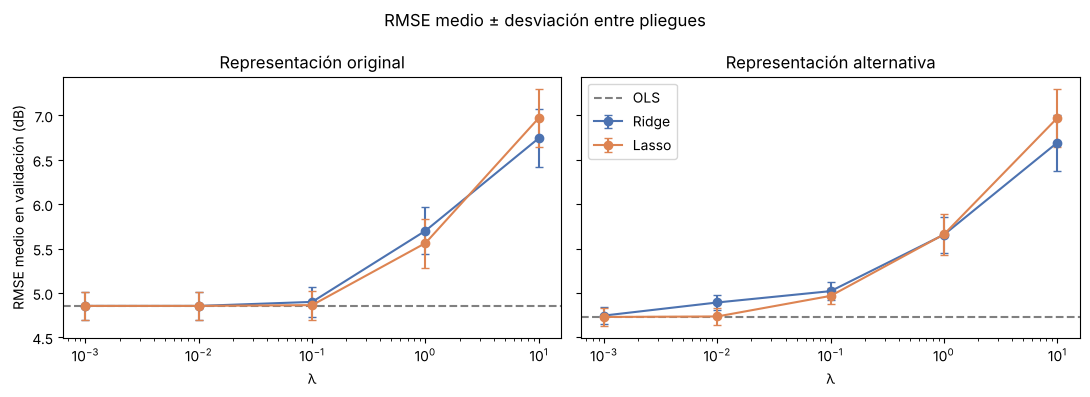

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, rep in zip(ejes, ["original", "alternativa"]):
    for modelo, color in [("Ridge", "#4C72B0"), ("Lasso", "#DD8452")]:
        r = resumen_cv.query("representacion == @rep and modelo == @modelo").sort_values("lam")
        eje.errorbar(r["lam"], r["rmse_medio"], yerr=r["rmse_de"], marker="o", capsize=3,
                     color=color, label=modelo)
    ols = resumen_cv.query("representacion == @rep and modelo == 'OLS'")["rmse_medio"].iloc[0]
    eje.axhline(ols, color="gray", ls="--", label="OLS")
    eje.set(xscale="log", xlabel="λ", title=f"Representación {rep}")
ejes[0].set_ylabel("RMSE medio en validación (dB)")
ejes[1].legend()
fig.suptitle("RMSE medio ± desviación entre pliegues")
fig.tight_layout()

In [24]:
# ¿La mejora de la representación alternativa se repite en cada pliegue? (OLS en ambas)
ols_por_pliegue = cv.query("modelo == 'OLS'").pivot(index="pliegue", columns="representacion", values="rmse")
ols_por_pliegue["diferencia_alt_menos_orig"] = ols_por_pliegue["alternativa"] - ols_por_pliegue["original"]
ols_por_pliegue.round(3)

representacion,alternativa,original,diferencia_alt_menos_orig
pliegue,,,
0,4.719,4.832,-0.112
1,4.913,5.093,-0.180
2,4.659,4.656,0.003
3,4.676,4.827,-0.150
4,4.681,4.865,-0.184


**Lectura.** La representación alternativa baja el RMSE de OLS de 4,85 a 4,73 dB, y la mejora aparece en
cuatro de los cinco pliegues (en el otro, la diferencia es 0,003 dB). Es una ganancia pequeña pero
consistente, que coincide con lo que mostró el EDA sobre la frecuencia.

La regularización casi no ayuda: con λ ≤ 0,01, Ridge y Lasso quedan a menos de 0,02 dB de OLS, y con λ ≥ 1
empeoran claramente. Tiene sentido: hay 961 filas de entrenamiento por pliegue y solo 5 o 6 variables, así
que OLS ya es estable. Con λ = 10, Lasso anula todos los coeficientes y queda igual a la referencia media.

Las diferencias entre los mejores candidatos (≈ 0,01 dB) son mucho menores que la variación entre
pliegues (≈ 0,1 dB). La desviación entre pliegues no es un intervalo de confianza, pero sí indica que
esas diferencias no permiten distinguir entre los candidatos.

In [25]:
# Selección con la regla fijada antes
reg = resumen_cv.query("modelo in ['Ridge', 'Lasso']").copy()
mejor = reg["rmse_medio"].min()
empatados = reg.loc[reg["rmse_medio"] - mejor < TOL_EMPATE].copy()
empatados["es_ridge"] = empatados["modelo"] == "Ridge"
elegido = empatados.sort_values(["lam", "es_ridge"], ascending=[False, False]).iloc[0]

REP_FINAL = elegido["representacion"]
MODELO_FINAL = elegido["modelo"]
LAM_FINAL = float(elegido["lam"])

display(empatados.drop(columns="es_ridge").round(4))
print(f"Seleccionado: {MODELO_FINAL} con λ = {LAM_FINAL:g}, representación {REP_FINAL}")
ols_misma = resumen_cv.query("representacion == @REP_FINAL and modelo == 'OLS'")["rmse_medio"].iloc[0]
print(f"OLS en la misma representación: RMSE medio = {ols_misma:.4f}")

,representacion,modelo,lam,rmse_medio,rmse_de,mae_medio,mae_de
2,alternativa,Lasso,0.001,4.7296,0.1042,3.5940,0.1360
3,alternativa,Lasso,0.010,4.7355,0.0977,3.6149,0.1375


Seleccionado: Lasso con λ = 0.01, representación alternativa
OLS en la misma representación: RMSE medio = 4.7296


## 6c. Evaluación final en prueba

La representación y los hiperparámetros quedan congelados. Los finalistas se ajustan sobre todo el
desarrollo y se evalúan una sola vez en prueba. Primero se guarda el manifiesto.

In [26]:
f_rep = REPRESENTACIONES[REP_FINAL]
escalador_final = StandardScaler().fit(f_rep(dev))
X_dev = escalador_final.transform(f_rep(dev))

finalistas = {
    "Referencia media": None,
    "OLS": OLS().fit(X_dev, y_dev),
    f"{MODELO_FINAL} (λ={LAM_FINAL:g})": (Ridge(lambda2=LAM_FINAL) if MODELO_FINAL == "Ridge"
                                          else LassoProximal(lambda1=LAM_FINAL, tol=1e-6, max_iter=50_000)
                                          ).fit(X_dev, y_dev),
}
media_dev = float(y_dev.mean())
mediana_dev = float(np.median(y_dev))

manifiesto_modelo = {
    "representacion": REP_FINAL,
    "variables": NOMBRES_X[REP_FINAL],
    "escalador": {"media": escalador_final.mean_.tolist(), "desviacion": escalador_final.scale_.tolist()},
    "modelo_regularizado": MODELO_FINAL,
    "lambda": LAM_FINAL,
    "grilla": GRILLA,
    "regla": "menor RMSE medio en CV de 5 pliegues; empate < 0.01 dB -> mayor lambda, luego Ridge",
    "referencia_media": media_dev,
    "referencia_mediana": mediana_dev,
    "coeficientes": {n: {"w": m.w_.tolist(), "b": m.b_} for n, m in finalistas.items() if m is not None},
}
with open(RUTA_RES / "airfoil_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(manifiesto_modelo, f, ensure_ascii=False, indent=2)

pd.DataFrame({n: m.w_ for n, m in finalistas.items() if m is not None},
             index=NOMBRES_X[REP_FINAL]).round(3)

,OLS,Lasso (λ=0.01)
log_f,19.373,16.046
log_f2,-23.228,-19.892
angulo,-2.386,-2.353
cuerda,-3.242,-3.218
velocidad,1.575,1.545
espesor,-2.122,-2.137


In [27]:
# Única evaluación en prueba
X_test = escalador_final.transform(f_rep(test))
y_test = test[OBJETIVO].to_numpy(dtype=float)

pred_test = {n: (np.full(len(test), media_dev) if m is None else m.predict(X_test))
             for n, m in finalistas.items()}


def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)


metricas = pd.DataFrame({n: {"MAE": mae(y_test, p), "RMSE": rmse(y_test, p), "R2": r2(y_test, p)}
                         for n, p in pred_test.items()}).T
metricas.loc["Referencia mediana"] = [mae(y_test, np.full(len(test), mediana_dev)), np.nan, np.nan]
metricas.round(3)

,MAE,RMSE,R2
Referencia media,5.309,6.597,-0.000
OLS,3.448,4.483,0.538
Lasso (λ=0.01),3.438,4.459,0.543
Referencia mediana,5.260,NaN,NaN


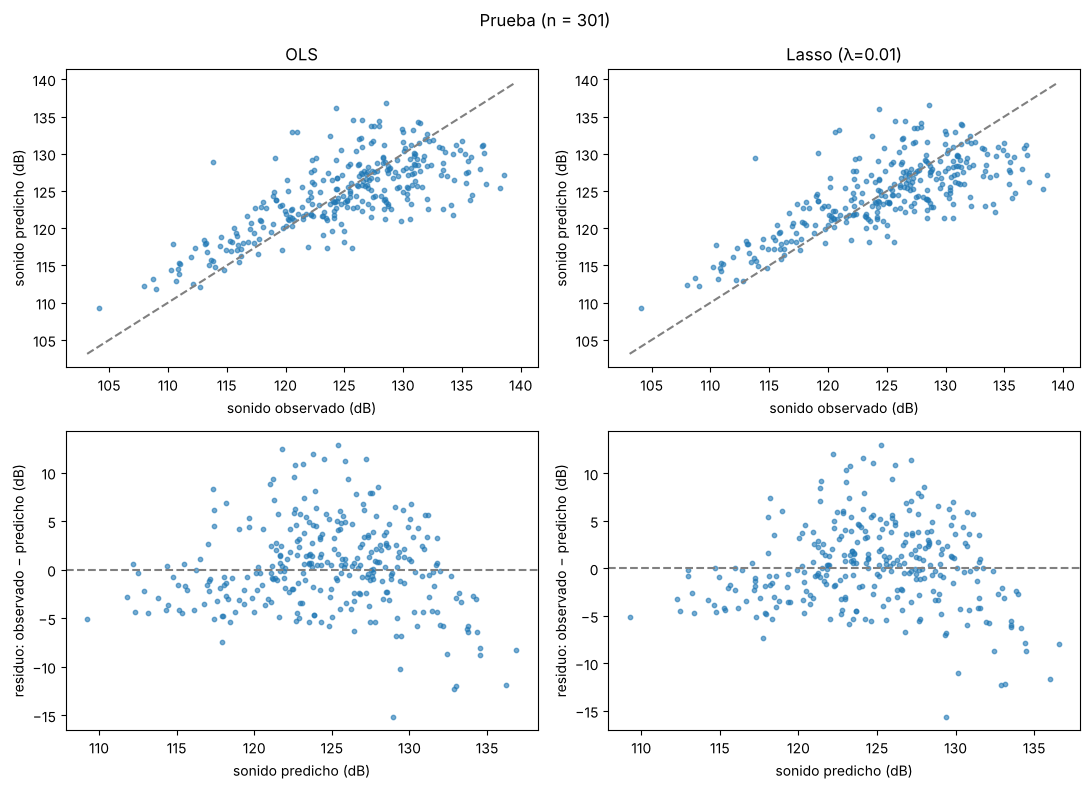

In [28]:
nombre_reg = list(finalistas)[2]
fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
for col, nombre in enumerate(["OLS", nombre_reg]):
    p = pred_test[nombre]
    lim = [min(y_test.min(), p.min()) - 1, max(y_test.max(), p.max()) + 1]
    ejes[0, col].scatter(y_test, p, s=10, alpha=0.6)
    ejes[0, col].plot(lim, lim, color="gray", ls="--")
    ejes[0, col].set(xlabel="sonido observado (dB)", ylabel="sonido predicho (dB)", title=nombre)
    ejes[1, col].scatter(p, y_test - p, s=10, alpha=0.6)
    ejes[1, col].axhline(0, color="gray", ls="--")
    ejes[1, col].set(xlabel="sonido predicho (dB)", ylabel="residuo: observado − predicho (dB)")
fig.suptitle(f"Prueba (n = {len(test)})")
fig.tight_layout()

In [29]:
# Errores por segmento (umbral de frecuencia fijado con desarrollo en la sección 5)
seg_test = segmento(test)
filas = []
for nombre, p in pred_test.items():
    for s in ["frecuencia_baja", "frecuencia_alta"]:
        m = seg_test == s
        filas.append(dict(modelo=nombre, segmento=s, n=int(m.sum()),
                          MAE=mae(y_test[m], p[m]), RMSE=rmse(y_test[m], p[m]),
                          residuo_medio=float(np.mean(y_test[m] - p[m]))))
pd.DataFrame(filas).round(3)

,modelo,segmento,n,MAE,RMSE,residuo_medio
0,Referencia media,frecuencia_baja,150,4.432,5.354,2.608
1,Referencia media,frecuencia_alta,151,6.180,7.634,-2.506
2,OLS,frecuencia_baja,150,4.047,5.137,0.526
3,OLS,frecuencia_alta,151,2.853,3.722,-0.032
4,Lasso (λ=0.01),frecuencia_baja,150,4.049,5.124,0.516
5,Lasso (λ=0.01),frecuencia_alta,151,2.831,3.680,-0.059


In [30]:
# Residuo medio de OLS por frecuencia: ¿hay errores sistemáticos?
res_ols = pd.DataFrame({"frecuencia": test["frecuencia"], "residuo": y_test - pred_test["OLS"]})
(res_ols.groupby("frecuencia")["residuo"].agg(["count", "mean"]).round(2)
        .rename(columns={"count": "n", "mean": "residuo_medio"}).T)

frecuencia,200,250,315,400,500,630,800,1000,1250,1600,...,2500,3150,4000,5000,6300,8000,10000,12500,16000,20000
n,7.00,6.0,13.0,19.00,15.00,18.00,12.00,19.0,20.00,21.00,...,19.00,18.00,21.00,19.00,13.00,10.00,15.00,3.00,3.00,3.00
residuo_medio,2.43,-2.0,2.3,0.69,-0.66,0.65,-1.95,1.7,0.05,0.91,...,-0.61,0.81,-1.72,0.74,-0.63,0.72,-0.15,2.62,5.24,3.78


In [31]:
predicciones = pd.DataFrame({"id": test["id"], "sonido_observado": y_test, "segmento": seg_test})
for nombre, p in pred_test.items():
    predicciones[f"pred_{nombre}"] = p
predicciones.to_csv(RUTA_RES / "airfoil_predicciones_prueba.csv", index=False)
predicciones.head()

,id,sonido_observado,segmento,pred_Referencia media,pred_OLS,pred_Lasso (λ=0.01)
0,14,126.416,frecuencia_baja,124.827524,127.430827,127.488051
1,19,126.986,frecuencia_baja,124.827524,125.377074,125.141639
2,21,124.106,frecuencia_alta,124.827524,123.545741,123.347872
3,44,116.229,frecuencia_alta,124.827524,116.255491,116.430586
4,45,114.779,frecuencia_alta,124.827524,114.395997,114.717481


**Lectura.** En prueba, OLS y Lasso (λ = 0,01) quedan prácticamente iguales: RMSE de 4,48 y 4,46 dB, R² de
0,54. Ambos superan con claridad a la referencia media (RMSE 6,60 dB). El RMSE en prueba es algo menor
que en validación cruzada; con 301 filas, esa diferencia está dentro de la variación esperada.

Hay errores sistemáticos. En la gráfica de predicho frente a observado, la nube es más plana que la
diagonal: el modelo sobreestima los ruidos bajos y subestima los altos. Los residuos frente a la
predicción tienen forma de arco: son negativos en los extremos y más dispersos en el centro. Eso indica
estructura no lineal que el modelo no capta, por ejemplo interacciones entre frecuencia, cuerda y velocidad.

Por segmentos, el error es mayor en frecuencia baja (RMSE 5,1 dB) que en frecuencia alta (3,7 dB), y en
frecuencia baja el modelo subestima en promedio unos 0,5 dB. Las tres frecuencias más altas (12 500 a
20 000 Hz) tienen residuos medios de 2,6 a 5,2 dB, pero con solo 3 mediciones cada una.

Estos resultados se reportan sin reajustar nada: la representación y λ quedaron fijados por la
validación cruzada.

## 6d. Alcance de la evaluación y elección del modelo

**Qué escenario representa la partición.** La partición aleatoria reparte mediciones individuales.
Como cada condición del ensayo (perfil, ángulo, velocidad) se midió a muchas frecuencias, casi todas
las condiciones de prueba también aparecen en desarrollo, solo que a otras frecuencias. Lo que se
evaluó es la capacidad de **interpolar** dentro de condiciones ya vistas: predecir el ruido a una
frecuencia no medida de un ensayo conocido.

**Cómo evaluar condiciones nuevas.** Para saber si el modelo sirve en un ensayo que nunca vio, hay que
partir por grupos y no por filas, por ejemplo:

- dejar fuera ensayos completos (todas las frecuencias de una misma combinación de cuerda, ángulo y
  velocidad), con `GroupKFold` usando esa combinación como grupo;
- dejar fuera una cuerda o una velocidad entera, para medir extrapolación a perfiles o flujos nuevos.

Lo esperable es un error mayor que el de este informe. La evaluación realizada no demuestra esa
capacidad.

**Evidencia para elegir entre OLS, Ridge y Lasso.** Por la regla fijada, el candidato regularizado es
Lasso con λ = 0,01 en la representación alternativa. Pero la evidencia no lo distingue de OLS: en
validación cruzada difieren en 0,006 dB, frente a una variación entre pliegues de 0,1 dB, y en prueba en
0,02 dB. Con muchas más filas que variables, la regularización tiene poco que corregir. Lasso tampoco
eliminó ninguna variable con λ = 0,01. Lo que sí tiene respaldo es el cambio de representación, que
mejoró en casi todos los pliegues. Si hubiera que elegir uno, OLS sería igual de bueno y más simple de
explicar.

**Sobre los coeficientes.** Son asociaciones dentro de este diseño experimental, no efectos causales.
Además, `angulo` y `espesor` están muy relacionadas (ρ = 0,87), así que el coeficiente de cada una
depende de que la otra esté en el modelo.